In [1]:
Plots.default(
    titlefontsize  = 16,   #título de cada gráfico
    guidefontsize  = 14,   #nombre de los ejes ("Tiempo t [s]")
    tickfontsize   = 12,   #números de los ejes
    legendfontsize = 12,   #leyenda
    linewidth      = 2.5,
    framestyle     = :box,
    fontfamily     = "Computer Modern",   #mismo estilo que LaTeX
    margin         = 5Plots.mm,
)
#import Pkg; Pkg.add("LaTeXStrings")

LoadError: UndefVarError: `Plots` not defined in `Main`
Suggestion: check for spelling errors or missing imports.

In [17]:
using LinearAlgebra
import DifferentialEquations as DE
using Plots
using LaTeXStrings

const Vc = 300.0             
const T_final = 10.0        
const epsilon = 1e-4       
const max_accel = 10 * 9.81 

A = [0.0 1.0; 
     0.0 0.0]
B = [0.0, -1.0]

#Modelo lineal (PNG con N = 3)
function ley_control_optimo(x, t)
    t_go = max(T_final - t, epsilon)
    y, y_dot = x[1], x[2]
    
    zem = y + y_dot * t_go
    u_opt = (3.0 / (t_go^2)) * zem
    return clamp(u_opt, -max_accel, max_accel)
end

#Dinámica Continua
function dinamica_guiado!(dx, x, p, t)
    u = ley_control_optimo(x, t)
    dx[1] = x[2]
    dx[2] = -u
end

#Solución Numérica (con ZEM(0) != 0 para que haya maniobra)
x0 = [200.0, 10.0]
tspan = (0.0, T_final - epsilon)
prob = DE.ODEProblem(dinamica_guiado!, x0, tspan)
sol = DE.solve(prob, DE.Tsit5(), reltol=1e-8, abstol=1e-8)

println("Distancia de fallo final y(T): ", abs(sol[1, end]), " m")
u_valores = [ley_control_optimo(sol.u[i], sol.t[i]) for i in 1:length(sol.t)]

#Observador de Luenberger (Guidance Filter)
function din_observador!(dz, z, p, t)
    x = z[1:2]
    x_hat = z[3:4]
    t_go = max(T_final - t, epsilon)
    

    u = ley_control_optimo(x_hat, t)
    
    C_t = [1.0 / (Vc * t_go)  0.0]
    y_m = (C_t * x)[1]
    
    l1, l2 = -7.0, -12.0
    L_t = [l1 * Vc * t_go, l2 * Vc * t_go]
    
    dz[1:2] = A * x + B * u
    dz[3:4] = A * x_hat + B * u + L_t * ((C_t * x_hat)[1] - y_m)
end

z0_obs = [200.0, 10.0, 170.0, -15.0]
sol_obs = DE.solve(DE.ODEProblem(din_observador!, z0_obs, tspan), DE.Tsit5(), reltol=1e-8)

# Gráficas
p1 = Plots.plot(sol.t, sol[1, :], xlabel="Tiempo t [s]", ylabel=L"$y(t)$ [m]",
                title="Separación Vertical Relativa", label=L"$y(t)$ real", lw=2, color=:blue)
Plots.plot!(p1, sol_obs.t, sol_obs[3, :], label=L"$\widehat{y}(t)$ observador", ls=:dash, lw=2, color=:red)

p2 = Plots.plot(sol.t, sol[2, :], xlabel="Tiempo t [s]", ylabel=L"$dy/dt$ [m/s]",
                title="Velocidad Relativa", label=L"$\dot{y}$ real", lw=2, color=:orange)
Plots.plot!(p2, sol_obs.t, sol_obs[4, :], label=L"$\dot{\widehat{y}}$ observador", ls=:dash, lw=2, color=:purple)

p3 = Plots.plot(sol.t, u_valores, xlabel="Tiempo t [s]", ylabel=L"$a_M(t)$ [m/$s^{2}$]",
                title=L"Aceleración del proyectil $u^{*}$", legend=false, lw=2, color=:red)

Plots.plot(p1, p2, p3, layout=(3, 1), size=(600, 1200))

savefig(p1, "posicionlineal.png")
savefig(p2, "velocidadlineal.png")
savefig(p3, "aceleracionlineal.png")


Distancia de fallo final y(T): 0.00349999998519942 m


"C:\\Users\\anton\\Documents\\Asignaturas\\MA4703 Control Óptimo\\aceleracionlineal.png"

2. MODELO NO LINEAL
Tiempo impacto HJB (N=3): 10.815 s | Distancia fallo: 0.5 m
Tiempo impacto PNG (N=4): 10.802 s | Distancia fallo: 0.5 m


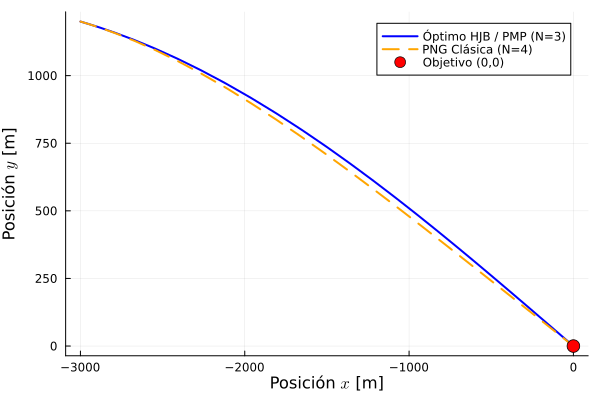

In [23]:
#const a_max = 100 * 9.81 

#2. Modelo no lineal 2D: HJB/Pontryagin vs PNG Clásica (objetivo fijo en (0,0))
#Estado: [x_M, y_M, gamma_M]
function din_nolineal!(dx, x, p, t)
    vp, modo = p
    rx, ry = -x[1], -x[2]
    R = hypot(rx, ry)
    if R < 0.5
        dx .= 0.0
        return
    end
    
    lambda = atan(ry, rx)
    sigma = atan(sin(x[3] - lambda), cos(x[3] - lambda))
    lambda_dot = -(vp * sin(sigma)) / R
    
    if modo == :HJB
        # Ley óptima exacta HJB: a_M = -(3 * vp^2 / R) * sin(sigma) = 3 * vp * lambda_dot
        a_M = -(3.0 * vp^2 / R) * sin(sigma)
    else
        # PNG clásica con N = 4 y Vc = vp * cos(sigma)
        Vc_nl = max(vp * cos(sigma), 10.0)
        a_M = 4.0 * Vc_nl * lambda_dot
    end
    #a_M = clamp(a_M, -a_max, a_max)
    
    dx[1] = vp * cos(x[3])
    dx[2] = vp * sin(x[3])
    dx[3] = a_M / vp
end

condicion_impacto(u, t, integrator) = hypot(u[1], u[2]) - 0.5
afectar_impacto!(integrator) = DE.terminate!(integrator)
cb_impacto = DE.ContinuousCallback(condicion_impacto, afectar_impacto!)

x0_nl = [-3000.0, 1200.0, deg2rad(-10.0)]
sol_hjb = DE.solve(DE.ODEProblem(din_nolineal!, x0_nl, (0.0, 20.0), (300.0, :HJB)),
                   DE.Tsit5(), callback=cb_impacto, reltol=1e-8)
sol_png = DE.solve(DE.ODEProblem(din_nolineal!, x0_nl, (0.0, 20.0), (300.0, :PNG)),
                   DE.Tsit5(), callback=cb_impacto, reltol=1e-8)

println("2. MODELO NO LINEAL")
println("Tiempo impacto HJB (N=3): ", round(sol_hjb.t[end], digits=3), " s | Distancia fallo: ",
        round(hypot(sol_hjb[1, end], sol_hjb[2, end]), digits=3), " m")
println("Tiempo impacto PNG (N=4): ", round(sol_png.t[end], digits=3), " s | Distancia fallo: ",
        round(hypot(sol_png[1, end], sol_png[2, end]), digits=3), " m")

#Gráfica comparativa de trayectorias 2D
Plots.plot(sol_hjb[1, :], sol_hjb[2, :], label="Óptimo HJB / PMP (N=3)", lw=2, color=:blue,
           xlabel=L"Posición $x$ [m]", ylabel=L"Posición $y$ [m]", title="")
Plots.plot!(sol_png[1, :], sol_png[2, :], label="PNG Clásica (N=4)", lw=2, ls=:dash, color=:orange)
Plots.scatter!([0.0], [0.0], label="Objetivo (0,0)", markersize=7, color=:red)

In [4]:
function din_dos!(dx, x, r_val, t)
    t_go = max(T_final - t, epsilon)
    
    y1, yd1, y2, yd2 = x[1], x[2], x[3], x[4]
    s, sd = y1 + y2, yd1 + yd2
    d, dd = y1 - y2, yd1 - yd2
    
    # Control óptimo desacoplado en suma (s(T)=0) y diferencia (d(T)=0, d'(T)=r)
    u_s = (3.0 / t_go^2) * (s + sd * t_go)
    u_d = (6.0 / t_go^2) * (d + dd * t_go) - (2.0 / t_go) * (dd - r_val)
    
    u1 = clamp(0.5 * (u_s + u_d), -25*9.81, 25*9.81)
    u2 = clamp(0.5 * (u_s - u_d), -25*9.81, 25*9.81)
    
    dx[1] = yd1; dx[2] = -u1
    dx[3] = yd2; dx[4] = -u2
end

theta_des = deg2rad(20.0) # Ángulo relativo de impacto deseado = 20 grados
r_req = Vc * theta_des
x0_2m = [250.0, -10.0, -200.0, 15.0]
sol_2m = DE.solve(DE.ODEProblem(din_dos!, x0_2m, tspan, r_req), DE.Tsit5(), reltol=1e-8)

theta_real = (sol_2m[2, end] - sol_2m[4, end]) / Vc
println("y1(T) = ", round(sol_2m[1, end], digits=4), " m, y2(T) = ", round(sol_2m[3, end], digits=4), " m")
println("Ángulo deseado: ", round(rad2deg(theta_des), digits=2), "° | Ángulo logrado: ",
        round(rad2deg(theta_real), digits=2), "°")

y1(T) = -0.0047 m, y2(T) = 0.0057 m
Ángulo deseado: 20.0° | Ángulo logrado: 20.0°


=== 4. N=3(Td = 13.5 s) ===
Guiado 1 -> Distancia al blanco en t = 13.5 s: 0.5 m
Guiado 2 -> Distancia al blanco en t = 13.5 s: 0.5 m
Guiado 3 -> Distancia al blanco en t = 13.5 s: 0.5 m


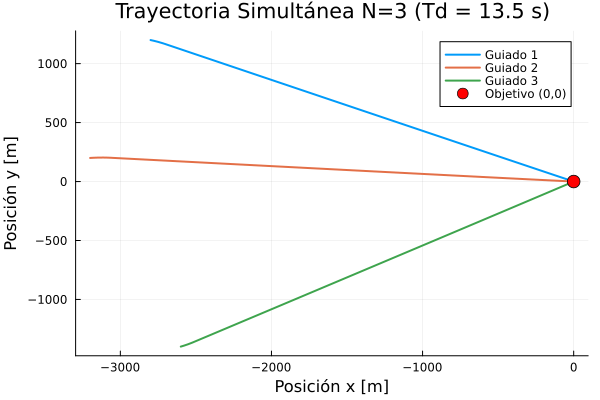

In [5]:
function din_n!(dx, x, p, t)
    N_mis, Td, vp, KT = p
    N_nav = 3.0
    for i in 1:N_mis
        idx = 3*(i-1)
        rx, ry = -x[idx+1], -x[idx+2]
        R = hypot(rx, ry)
        if R < 0.5
            dx[idx+1:idx+3] .= 0.0
            continue
        end
        
        lambda = atan(ry, rx)
        sigma = atan(sin(x[idx+3] - lambda), cos(x[idx+3] - lambda))
        lambda_dot = -(vp * sin(sigma)) / R
        
        # Estimación analítica precisa de t_go bajo PNG (Jeon et al., 2006)
        t_go_est = (R / vp) * (1.0 + (sigma^2) / (2.0 * (2.0 * N_nav - 1.0)))
        err_T = Td - (t + t_go_est)
        
        # Dirección de curvatura para alargar/acortar trayectoria sin singularidad en sigma = 0
        dir_curva = abs(sigma) < 1e-3 ? 1.0 : sign(sigma)
        
        # Ley ITCG: PNG (N=3) + término de sincronización de tiempo de impacto
        a_png = N_nav * vp * lambda_dot
        a_tiempo = -dir_curva * KT * (vp / max(t_go_est, 0.2)^2) * err_T
        
        a_M = clamp(a_png + a_tiempo, -25.0*9.81, 25.0*9.81)
        
        dx[idx+1] = vp * cos(x[idx+3])
        dx[idx+2] = vp * sin(x[idx+3])
        dx[idx+3] = a_M / vp
    end
end

Td_obj = 13.5 # Tiempo simultáneo de impacto deseado [s]
x0_3m = [
    -2800.0,  1200.0, deg2rad(-15.0),
    -3200.0,   200.0, deg2rad(5.0),
    -2600.0, -1400.0, deg2rad(20.0)
]

# KT = 12.0 regula la rapidez con la que se anula el error de tiempo de llegada
sol_3m = DE.solve(DE.ODEProblem(din_n!, x0_3m, (0.0, Td_obj), (3, Td_obj, 300.0, 12.0)),
                  DE.Tsit5(), reltol=1e-8)

println("=== 4. N=3(Td = $Td_obj s) ===")
for i in 1:3
    idx = 3*(i-1)
    R_fin = hypot(sol_3m[idx+1, end], sol_3m[idx+2, end])
    println("Guiado $i -> Distancia al blanco en t = $Td_obj s: ", round(R_fin, digits=3), " m")
end

#Gráfica de las trayectorias convergentes al mismo instante Td = 13.5 s
p_multi = Plots.plot(xlabel="Posición x [m]", ylabel="Posición y [m]",
                     title="Trayectoria Simultánea N=3 (Td = $(Td_obj) s)")
for i in 1:3
    idx = 3*(i-1)
    Plots.plot!(p_multi, sol_3m[idx+1, :], sol_3m[idx+2, :], label="Guiado $i", lw=2)
end
Plots.scatter!(p_multi, [0.0], [0.0], label="Objetivo (0,0)", markersize=7, color=:red)

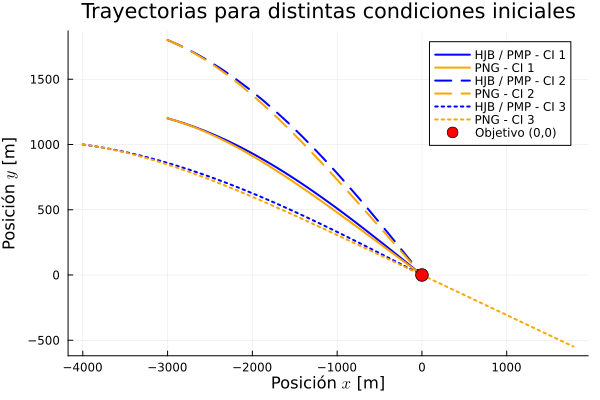

In [9]:
#Condiciones iniciales
condiciones_iniciales = [
    [-3000.0, 1200.0, deg2rad(-10.0)],
    [-3000.0, 1800.0, deg2rad(-15.0)],
    [-4000.0, 1000.0, deg2rad(-5.0)]
]


soluciones_hjb = []
soluciones_png = []

for x0 in condiciones_iniciales
    prob_hjb = DE.ODEProblem(din_nolineal!, x0, (0.0, 20.0), (300.0, :HJB))
    prob_png = DE.ODEProblem(din_nolineal!, x0, (0.0, 20.0), (300.0, :PNG))

    push!(soluciones_hjb, DE.solve(prob_hjb, DE.Tsit5(),
          callback=cb_impacto, reltol=1e-8))

    push!(soluciones_png, DE.solve(prob_png, DE.Tsit5(),
          callback=cb_impacto, reltol=1e-8))
end

#Gráfica comparativa de trayectorias 2D
p = Plots.plot(
    xlabel=L"Posición $x$ [m]",
    ylabel=L"Posición $y$ [m]",
    title="Trayectorias para distintas condiciones iniciales",
    legend=:best
)

for i in eachindex(condiciones_iniciales)
    Plots.plot!(p, soluciones_hjb[i][1, :], soluciones_hjb[i][2, :],
        label="HJB / PMP - CI $i",
        lw=2, color=:blue,
        ls=[:solid, :dash, :dot][i])

    Plots.plot!(p, soluciones_png[i][1, :], soluciones_png[i][2, :],
        label="PNG - CI $i",
        lw=2, color=:orange,
        ls=[:solid, :dash, :dot][i])
end

Plots.scatter!(p, [0.0], [0.0],
    label="Objetivo (0,0)", markersize=7, color=:red)

display(p)

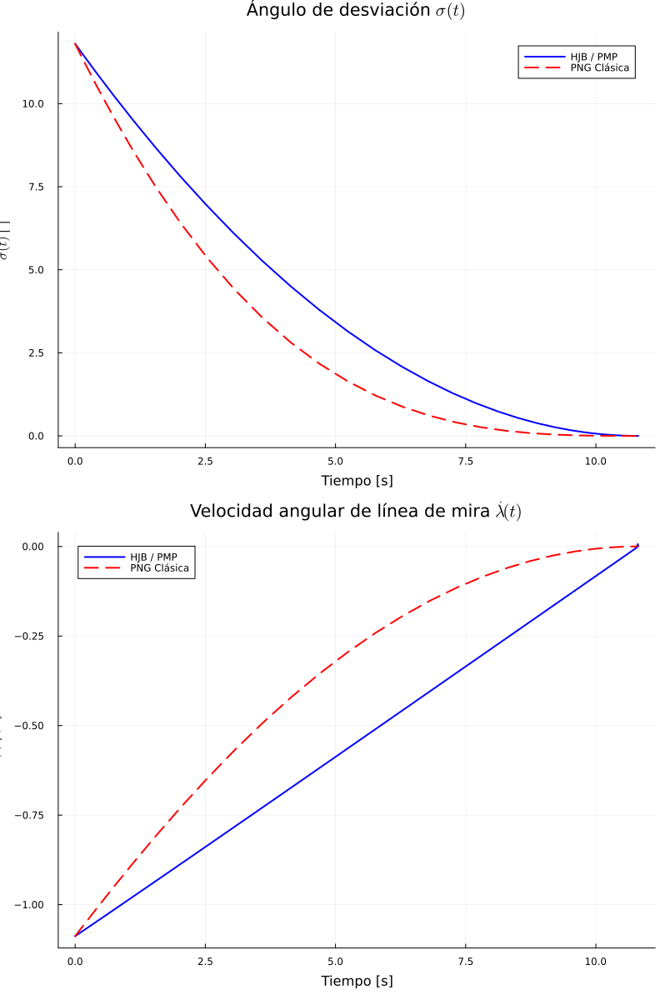

In [21]:
#Evolución angular del modelo no lineal
function parametros_angulares(sol, vp)
    sigma_valores = Float64[]
    lambda_dot_valores = Float64[]

    for i in eachindex(sol.t)
        x = sol.u[i]

        rx, ry = -x[1], -x[2]
        R = hypot(rx, ry)

        if R < 0.5
            push!(sigma_valores, NaN)
            push!(lambda_dot_valores, NaN)
            continue
        end

        lambda = atan(ry, rx)

        sigma = atan(
            sin(x[3] - lambda),
            cos(x[3] - lambda)
        )

        lambda_dot = -(vp * sin(sigma)) / R

        push!(sigma_valores, rad2deg(sigma))
        push!(lambda_dot_valores, rad2deg(lambda_dot))
    end

    return sigma_valores, lambda_dot_valores
end

#Cálculo para ambos métodos
sigma_hjb, lambda_hjb = parametros_angulares(sol_hjb, 300.0)
sigma_png, lambda_png = parametros_angulares(sol_png, 300.0)

p_sigma = Plots.plot(
    sol_hjb.t, sigma_hjb,
    label="HJB / PMP",
    xlabel="Tiempo [s]",
    ylabel=L"\sigma(t)\ [^\circ]",
    title=L"Ángulo de desviación $\sigma(t)$",
    color=:blue,
    lw=2
)

Plots.plot!(p_sigma,
    sol_png.t, sigma_png,
    label="PNG Clásica",
    color=:red,
    lw=2,
    ls=:dash
)


p_lambda = Plots.plot(
    sol_hjb.t, lambda_hjb,
    label="HJB / PMP",
    xlabel="Tiempo [s]",
    ylabel=L"\dot{\lambda}(t)\ [^\circ/s]",
    title=L"Velocidad angular de línea de mira $\dot{\lambda}(t)$",
    color=:blue,
    lw=2
)

Plots.plot!(p_lambda,
    sol_png.t, lambda_png,
    label="PNG Clásica",
    color=:red,
    lw=2,
    ls=:dash
)

# Presentación conjunta
Plots.plot(
    p_sigma, p_lambda,
    layout=(2,1),
    size=(800,1200)
)